[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/09_trajectory_analysis.ipynb)

# 09 · Trajectory Analysis with MDAnalysis and MDTraj

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~60 min*

A trajectory is a movie with thousands of frames; analysis turns it into numbers and plots you can interpret and
report. We analyse three independent short (0.2 ns) simulations of the chignolin β-hairpin in water with the two most
popular Python libraries, **MDAnalysis** and **MDTraj**: RMSD, RMSF, radius of gyration, hydrogen bonds, and
secondary structure (DSSP). The same code works for any protein.

**Learning objectives.** By the end of this notebook you will be able to:

- load a topology and trajectory with MDAnalysis and MDTraj
- align frames and compute RMSD, per-residue RMSF, and radius of gyration
- find hydrogen bonds and their occupancy
- assign secondary structure per frame with DSSP and compare independent replicas

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'mdtraj', 'MDAnalysis', 'py3Dmol'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Load the trajectories

The precomputed files contain only the 166 peptide atoms (water was not saved), one frame every 2 ps. Set
`USE_OWN_TRAJECTORY = True` to analyse the short trajectory you produced in Notebook 08 instead.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import rms, align
import mdtraj as md

USE_OWN_TRAJECTORY = False
if USE_OWN_TRAJECTORY:
    TOP, DCDS = "output/chignolin_protein.pdb", ["output/production.dcd"]
else:
    TOP = f"{DATA_DIR}/trajectories/chignolin_protein.pdb"
    DCDS = [f"{DATA_DIR}/trajectories/chignolin_rep{i}.dcd" for i in range(3)]

FRAME_PS = 2.0                                   # time between saved frames (both sources)
universes = [mda.Universe(TOP, d, dt=FRAME_PS) for d in DCDS]
u = universes[0]
print(u)
print("residues:", " ".join(f"{r.resname}{r.resid}" for r in u.residues))
print("frames per replica:", [len(x.trajectory) for x in universes], "| time step between frames:", u.trajectory.dt, "ps")

<Universe with 166 atoms>
residues: TYR1 TYR2 ASP3 PRO4 GLU5 THR6 GLY7 THR8 TRP9 TYR10
frames per replica: [100, 100, 100] | time step between frames: 2.0 ps


/workspace/envs/practical-molecular-dynamics-course/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:176: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn(


MDAnalysis uses an `AtomGroup` + selection language (`"backbone"`, `"name CA"`, `"resid 3:8"`); MDTraj uses
NumPy arrays of coordinates (`traj.xyz`, in nm) and its own selection syntax. Both read all common formats
(DCD, XTC, TRR, NetCDF, PDB, ...).

## 2. RMSD: how far from the crystal structure?

Root-mean-square deviation after optimal superposition, $\text{RMSD} = \sqrt{\tfrac1N\sum_i |\mathbf{r}_i - \mathbf{r}_i^{ref}|^2}$.
The reference is the prepared crystal structure (the topology file).

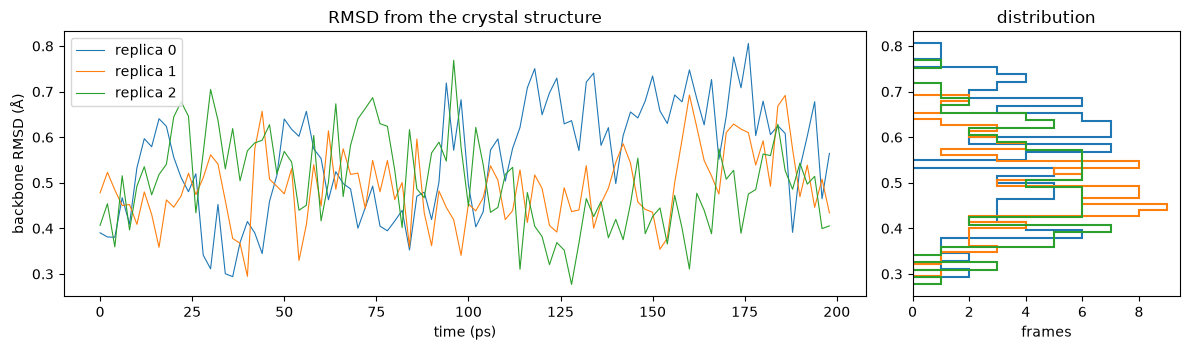

,backbone,CA_core
replica,,
0,0.55,0.51
1,0.49,0.41
2,0.50,0.43


In [3]:
ref = mda.Universe(TOP)
rmsd = {}
for i, uu in enumerate(universes):
    R = rms.RMSD(uu, ref, select="backbone", groupselections=["name CA and resid 2:9"]).run()
    rmsd[i] = pd.DataFrame(R.results.rmsd[:, [1, 2, 3]], columns=["time_ps", "backbone", "CA_core"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [3, 1]})
for i, d in rmsd.items():
    ax[0].plot(d.time_ps, d.backbone, lw=0.8, label=f"replica {i}")
    ax[1].hist(d.backbone, bins=30, histtype="step", lw=1.5, orientation="horizontal")
ax[0].set(xlabel="time (ps)", ylabel="backbone RMSD (Å)", title="RMSD from the crystal structure"); ax[0].legend()
ax[1].set(xlabel="frames", title="distribution")
plt.tight_layout(); plt.show()
pd.DataFrame({i: d[["backbone", "CA_core"]].mean() for i, d in rmsd.items()}).T.round(2).rename_axis("replica")

## 3. RMSF: which residues move?

Root-mean-square *fluctuation* measures how much each atom moves around its own average position. Frames must
first be aligned on a stable reference (here the Cα atoms), otherwise overall rotation would dominate.

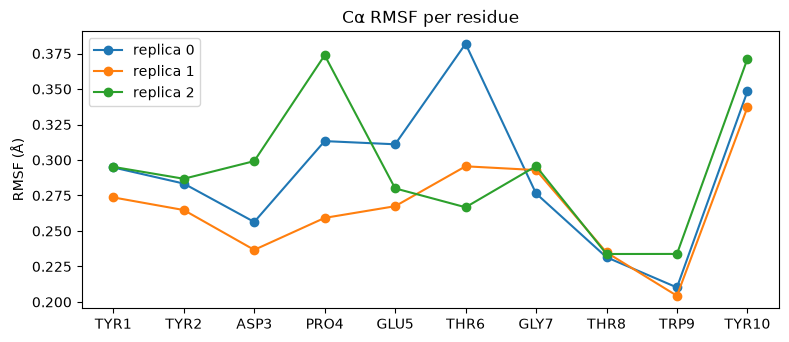

In [4]:
rmsf_rows = []
for i, uu in enumerate(universes):
    align.AlignTraj(uu, ref, select="name CA", in_memory=True).run()
    ca = uu.select_atoms("name CA")
    R = rms.RMSF(ca).run()
    rmsf_rows.append(pd.Series(R.results.rmsf, index=[f"{r.resname}{r.resid}" for r in ca.residues], name=f"replica {i}"))
rmsf = pd.concat(rmsf_rows, axis=1)
ax = rmsf.plot(marker="o", figsize=(9, 3.6), title="Cα RMSF per residue")
ax.set_xticks(range(len(rmsf))); ax.set_xticklabels(rmsf.index); ax.set_ylabel("RMSF (Å)")
plt.show()

All Cα RMSF values here are small (well under 0.5 Å): in 0.2 ns the hairpin only vibrates around its folded
structure. The C-terminal Tyr10 is among the most mobile residues in every replica, while which turn residue
(Pro4–Gly7) moves most differs between replicas, a reminder that short runs give noisy per-residue profiles. RMSF profiles are often
compared with crystallographic B-factors ($B = \tfrac{8\pi^2}{3}\,\text{RMSF}^2$) or NMR order parameters.

## 4. Radius of gyration: compact or unfolded?

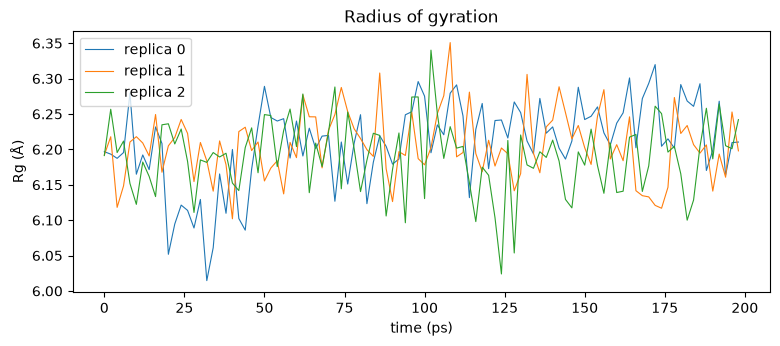

{'replica 0': '6.21 ± 0.06 Å', 'replica 1': '6.20 ± 0.05 Å', 'replica 2': '6.19 ± 0.05 Å'}


In [5]:
rg = {}
for i, uu in enumerate(universes):
    prot = uu.select_atoms("protein")
    rg[i] = np.array([prot.radius_of_gyration() for _ in uu.trajectory])
t = rmsd[0].time_ps.values
plt.figure(figsize=(9, 3.4))
for i, v in rg.items():
    plt.plot(t, v, lw=0.8, label=f"replica {i}")
plt.xlabel("time (ps)"); plt.ylabel("Rg (Å)"); plt.title("Radius of gyration"); plt.legend(); plt.show()
print({f"replica {i}": f"{v.mean():.2f} ± {v.std():.2f} Å" for i, v in rg.items()})

## 5. Hydrogen bonds

A β-hairpin is held together by backbone hydrogen bonds across the two strands. MDAnalysis'
`HydrogenBondAnalysis` uses geometric criteria. Here we count a hydrogen bond when the donor–acceptor distance is
≤ 3.5 Å and the donor–H–acceptor angle is ≥ 150°. Donors are the protein's N and O atoms, each hydrogen is paired with
the donor it is covalently bound to (within 1.2 Å), and acceptors are the O atoms. We report the occupancy (fraction of
frames) of each hydrogen bond.

In [6]:
from MDAnalysis.analysis.hydrogenbonds import HydrogenBondAnalysis

def label(atom):
    return f"{atom.resname}{atom.resid}:{atom.name}"

occ = []
for i, uu in enumerate(universes):
    uu_ = mda.Universe(TOP, DCDS[i], dt=FRAME_PS)     # fresh copy (unaligned) for clarity
    hba = HydrogenBondAnalysis(uu_, donors_sel="protein and (element N or element O)",
                               hydrogens_sel="protein and element H",
                               acceptors_sel="protein and element O",
                               d_h_cutoff=1.2, d_a_cutoff=3.5, d_h_a_angle_cutoff=150)
    hba.run()
    by_id = {atom.id: atom for atom in uu_.atoms}         # count_by_ids() returns atom IDs, not indices
    for d, h, a, count in hba.count_by_ids():
        occ.append({"replica": i, "donor": label(by_id[d]), "acceptor": label(by_id[a]),
                    "occupancy": count / len(uu_.trajectory)})
hb = pd.DataFrame(occ)
table = hb.pivot_table(index=["donor", "acceptor"], columns="replica", values="occupancy", fill_value=0)
table["mean"] = table.mean(axis=1)
table.sort_values("mean", ascending=False).head(10).round(2)

/workspace/envs/practical-molecular-dynamics-course/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:176: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn(


,replica,0,1,2,mean
donor,acceptor,,,,
ASP3:N,THR8:O,0.85,0.95,0.91,0.90
THR8:OG1,THR6:OG1,0.33,0.91,0.84,0.69
THR6:OG1,ASP3:OD1,0.87,0.90,0.29,0.69
TYR10:N,TYR1:O,0.64,0.58,0.59,0.60
THR8:N,THR6:OG1,0.35,0.53,0.60,0.49
GLU5:N,ASP3:OD2,0.33,0.50,0.34,0.39
THR6:N,ASP3:OD1,0.57,0.34,0.11,0.34
TYR1:N,TYR10:OXT,0.24,0.25,0.37,0.28
GLY7:N,ASP3:O,0.10,0.22,0.29,0.20


Backbone N–H···O=C hydrogen bonds between residues on opposite strands (and side-chain bonds involving Asp3, Glu5,
and the threonines in the turn) are the hairpin's "zipper". A hydrogen bond that is present in all replicas with
high occupancy is a robust structural feature; one seen in only one replica may be a rare fluctuation, and
deserves longer sampling before you interpret it.

## 6. Secondary structure with DSSP (MDTraj)

DSSP assigns each residue in each frame to helix (H), strand (E), or coil (C) from its hydrogen-bond pattern.

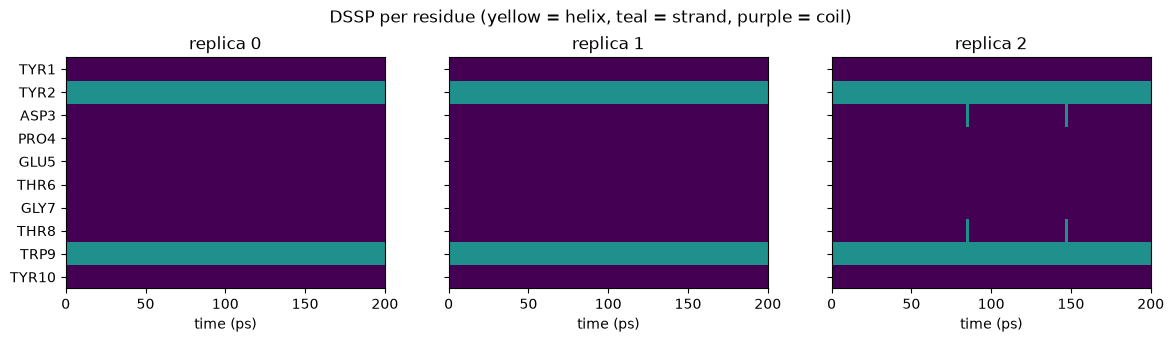

,TYR1,TYR2,ASP3,PRO4,GLU5,THR6,GLY7,THR8,TRP9,TYR10
replica 0,0.0,1.0,0.00,0.0,0.0,0.0,0.0,0.00,1.0,0.0
replica 1,0.0,1.0,0.00,0.0,0.0,0.0,0.0,0.00,1.0,0.0
replica 2,0.0,1.0,0.02,0.0,0.0,0.0,0.0,0.02,1.0,0.0


In [7]:
trajs = [md.load(d, top=TOP) for d in DCDS]
ss = [md.compute_dssp(tr, simplified=True) for tr in trajs]
codes = {"H": 2, "E": 1, "C": 0}
fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for i, (a, s) in enumerate(zip(axes, ss)):
    a.imshow(np.vectorize(codes.get)(s).T, aspect="auto", cmap="viridis", vmin=0, vmax=2, interpolation="nearest",
             extent=[0, trajs[i].n_frames * FRAME_PS, s.shape[1] - 0.5, -0.5])
    a.set(title=f"replica {i}", xlabel="time (ps)")
axes[0].set_yticks(range(10)); axes[0].set_yticklabels([str(r) for r in trajs[0].topology.residues])
plt.suptitle("DSSP per residue (yellow = helix, teal = strand, purple = coil)", y=1.04); plt.show()

strand = pd.DataFrame({f"replica {i}": (s == "E").mean(0) for i, s in enumerate(ss)},
                      index=[str(r) for r in trajs[0].topology.residues])
strand.round(2).T

In these short runs DSSP labels only Tyr2 and Trp9 as strand (E): a minimal two-residue β-bridge, with the rest of
this tiny peptide classified as coil. This is typical for chignolin, whose "strands" are very short, and it shows why
DSSP percentages should be read alongside the hydrogen-bond table above.

## 7. MDTraj and MDAnalysis agree

A quick cross-check: Cα RMSD to the crystal structure computed independently by both libraries.

In [8]:
ref_md = md.load(TOP)
ca_md = trajs[0].topology.select("name CA")
rmsd_md = md.rmsd(trajs[0], ref_md, atom_indices=ca_md) * 10
R = rms.RMSD(mda.Universe(TOP, DCDS[0], dt=FRAME_PS), ref, select="name CA").run()
print(f"max difference MDTraj vs MDAnalysis: {np.abs(rmsd_md - R.results.rmsd[:, 2]).max():.2e} Å")

max difference MDTraj vs MDAnalysis: 1.16e-05 Å


/workspace/envs/practical-molecular-dynamics-course/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:176: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn(


## 8. Look at the motion

In [9]:
try:
    import py3Dmol
    sel = trajs[0][::10]                      # every 20 ps
    os.makedirs("output", exist_ok=True)
    sel.superpose(sel, 0).save_pdb("output/chignolin_frames.pdb")
    v = py3Dmol.view(width=520, height=360)
    v.addModelsAsFrames(open("output/chignolin_frames.pdb").read(), "pdb")
    v.setStyle({"cartoon": {"color": "spectrum"}, "stick": {"radius": 0.12}})
    v.zoomTo(); v.animate({"loop": "backAndForth", "interval": 300}); v.show()
except ImportError:
    print("py3Dmol not installed; open output/chignolin_frames.pdb in PyMOL, ChimeraX, or VMD.")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### ✏️ Exercise 1

Compute the **end-to-end distance** (Tyr1 N to Tyr10 C) for every replica with MDTraj and plot its distribution.
Is the hairpin ever opening during these simulations?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for i, tr in enumerate(trajs):
    pair = [[tr.topology.select("resid 0 and name N")[0], tr.topology.select("resid 9 and name C")[0]]]
    d = md.compute_distances(tr, pair)[:, 0] * 10
    plt.hist(d, bins=30, histtype="step", label=f"replica {i}")
    print(f"replica {i}: {d.mean():.1f} ± {d.std():.1f} Å, max {d.max():.1f} Å")
plt.xlabel("end-to-end distance (Å)"); plt.legend(); plt.show()
```

</details>

### ✏️ Exercise 2

Compute the **fraction of native contacts** Q per frame: take all pairs of Cα atoms at least 3 residues apart that
are closer than 7 Å in the crystal structure, and count how many are within 1.2× their native distance in each frame.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
ca_idx = ref_md.topology.select("name CA")
pairs = np.array([(a, b) for k, a in enumerate(ca_idx) for b in ca_idx[k + 3:]])
d0 = md.compute_distances(ref_md, pairs)[0]
native = pairs[d0 < 0.7]; d0n = d0[d0 < 0.7]
for i, tr in enumerate(trajs):
    q = (md.compute_distances(tr, native) < 1.2 * d0n).mean(1)
    print(f"replica {i}: {len(native)} native contacts, mean Q = {q.mean():.2f}, min Q = {q.min():.2f}")
```

</details>

### ✏️ Exercise 3

Using `table`, list the hydrogen bonds whose occupancy differs by more than 0.3 between any two replicas. What
does this tell you about the sampling?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
reps = [c for c in table.columns if c != "mean"]
spread = table[reps].max(axis=1) - table[reps].min(axis=1)
print(table[spread > 0.3].round(2))
```

</details>

## Key takeaways

- MDAnalysis (AtomGroups, analysis classes) and MDTraj (NumPy arrays, fast functions) complement each other.
- Align before RMSF; RMSD needs a clear reference; Rg tracks compactness.
- Report hydrogen-bond occupancies and secondary structure fractions, and compare across replicas.
- Consistent results across independent replicas are the first sign of reliable sampling.

**Next:** [10 · Free energy landscapes](10_free_energy_landscapes.ipynb).